# Capstone Two: Modeling
## Retail demand forecasting for small businesses

**Author:** Jacob Paul
**Input:** the leakage-aware product-week development table from `03_preprocessing_and_training_data.ipynb` (`data/processed/preprocessing_v1/`)
**Output:** tuned regression models, a validation-based model choice, one final test evaluation, and metric/prediction files in `reports/modeling/`

### Forecasting contract 
At the start of each Monday, forecast total **units sold per product during that Monday–Sunday week** using information available through the previous Sunday. This is a **rolling one-week-ahead** forecast, not a seven-week forecast issued once. The target is recorded sales, not unconstrained demand: stockouts and discontinuations are not observed.

### What this notebook covers

| Requirement | Where |
|---|---|
| Consider model types that suit the features | Section 3 |
| Build two or three models from different algorithm families | Sections 4–5: ridge regression, random forest, histogram gradient boosting (XGBoost is added automatically when installed) |
| Hyperparameter tuning | Section 4: grid search with week-based, expanding-window cross-validation |
| Compare against naive baselines and choose a final model | Sections 2 and 5 |
| Compare predictions with actual outcomes | Sections 6 and 7 |
| Final evaluation on the reserved test weeks, once | Section 7 |

### Ground rules followed throughout
1. Weeks are never split across partitions. Tuning uses only the training weeks.
2. Preprocessing (imputation, scaling, product vocabulary) lives **inside** each model pipeline, so every cross-validation fold fits it on its own training weeks only.
3. The model is chosen on the **validation** weeks by a rule stated before any model is fitted (Section 5). The test weeks are not touched until Section 7.
4. The final model is refit on train + validation, with preprocessing refit on that combined past partition only, then scored on the test weeks once.

## 1. Setup and data

In [1]:
from pathlib import Path
import importlib.metadata
import json
import platform
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from xgboost import XGBRegressor
    XGB_AVAILABLE = True
except ImportError:
    XGB_AVAILABLE = False

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)
plt.style.use('ggplot')

roots = [Path.cwd(), Path.cwd().parent]
REPO_ROOT = next((p for p in roots if (p / 'notebooks').is_dir() and (p / 'data').is_dir()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Run from the repository root or notebooks/ directory.')
ARTIFACT_DIR = REPO_ROOT / 'data' / 'processed' / 'preprocessing_v1'
if not (ARTIFACT_DIR / 'development_dataset.csv.gz').exists():
    raise FileNotFoundError('Run 03_preprocessing_and_training_data.ipynb first to create the development table.')
REPORT_DIR = REPO_ROOT / 'reports' / 'modeling'
FIG_DIR = REPORT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
MONTH_CATEGORIES = [f'{m:02d}' for m in range(1, 13)]
packages = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib'] + (['xgboost'] if XGB_AVAILABLE else [])
versions = {p: importlib.metadata.version(p) for p in packages}
print('Python:', platform.python_version())
print('Package versions:', versions)
print('XGBoost available:', XGB_AVAILABLE)

Python: 3.14.6
Package versions: {'numpy': '2.4.6', 'pandas': '3.0.3', 'scipy': '1.18.0', 'scikit-learn': '1.9.0', 'matplotlib': '3.11.0'}
XGBoost available: False


In [2]:
development = pd.read_csv(
    ARTIFACT_DIR / 'development_dataset.csv.gz',
    dtype={'StockCode': str, 'Month': str, 'RowID': str},
    parse_dates=['WeekStart'],
).sort_values(['WeekStart', 'StockCode']).reset_index(drop=True)
manifest = json.loads((ARTIFACT_DIR / 'manifest.json').read_text())

NUMERIC_FEATURES = manifest['numeric_features']
CATEGORICAL_FEATURES = manifest['categorical_features']
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = manifest['target']

# The saved table must match what the preprocessing notebook recorded.
for split in manifest['splits']:
    rows = development.loc[development.Split.eq(split['split'])]
    assert len(rows) == split['rows'], split['split']
    assert rows.WeekStart.nunique() == split['weeks'], split['split']
assert development.groupby('WeekStart').Split.nunique().eq(1).all(), 'a week is split across partitions'
assert not development.duplicated(['StockCode', 'WeekStart']).any()
assert development[FEATURES + [TARGET]].notna().all().all()

train = development.loc[development.Split.eq('train')].reset_index(drop=True)
validation = development.loc[development.Split.eq('validation')].reset_index(drop=True)
assert train.WeekStart.max() < validation.WeekStart.min()

summary = pd.DataFrame([
    {'Split': 'train', 'Rows': len(train), 'Products': train.StockCode.nunique(),
     'First week': train.WeekStart.min().date(), 'Last week': train.WeekStart.max().date(),
     'Mean units': train[TARGET].mean(), 'Share of zero weeks': train[TARGET].eq(0).mean()},
    {'Split': 'validation', 'Rows': len(validation), 'Products': validation.StockCode.nunique(),
     'First week': validation.WeekStart.min().date(), 'Last week': validation.WeekStart.max().date(),
     'Mean units': validation[TARGET].mean(), 'Share of zero weeks': validation[TARGET].eq(0).mean()},
])
display(summary.round(3))
print(f"Final test rows held back until Section 7: {development.Split.eq('test').sum():,}")
print('Predictors:', FEATURES)

,Split,Rows,Products,First week,Last week,Mean units,Share of zero weeks
0,train,83092,3084,2011-01-10,2011-08-22,31.375,0.361
1,validation,22191,3239,2011-08-29,2011-10-10,38.169,0.378


Final test rows held back until Section 7: 23,511
Predictors: ['UnitsLag1', 'UnitsLag2', 'UnitsLag4', 'RollingMean4', 'RollingStd4', 'ZeroWeeksLast4', 'WeeksSinceFirstSale', 'PriorSellingWeeks', 'LastObservedUnitPrice', 'WeekSin', 'WeekCos', 'StockCode', 'Month']


**What the target looks like.** Weekly units are a count with a long right tail: more than a third of product-weeks have zero recorded sales, the median is only a few units, and a handful of bulk-order weeks reach thousands of units. Two consequences shape the modeling choices below:

- **MAE** (average miss in units per product-week) is the headline metric because it is easy to explain to a shop owner and is the success criterion in the proposal. **RMSE** and **R²** are reported too, but they are dominated by the few very large weeks.
- A model can lower MAE by predicting typical values and ignoring the extremes, so the loss function is itself a modeling choice. The tuning grid includes squared-error, absolute-error and Poisson losses for the boosted trees.

## 2. Metrics and naive baselines

Forecasts are post-processed as in the proposal: clipped at zero and rounded to the nearest whole unit, because a business cannot stock a fraction of a unit. All reported metrics use these rounded forecasts.

| Metric | Meaning |
|---|---|
| MAE | mean absolute error, units per product-week |
| RMSE | root mean squared error, units |
| R² | share of variance in weekly units explained, relative to predicting the overall mean |
| WAPE | total absolute error divided by total actual units (error relative to volume) |
| Within ±20% | share of forecasts within 20% of the actual value. This is the proposal's business metric and is strict: when actual sales are zero, only a forecast of zero counts. |
| Within ±20% or 5 units | same, but a miss of up to 5 units always counts. This is fairer for slow sellers, where 20% of 3 units is less than one unit. |
| Mean error | forecast minus actual, averaged. Negative means the model under-forecasts on average. |

**Baselines.** The proposal names the per-product training average as the baseline. Two simpler rules that use the same information available at forecast time are added, because they are much harder to beat: repeat last week, and use the four-week average.

In [3]:
def forecast_metrics(y_true, y_pred, round_forecast=True):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.clip(np.asarray(y_pred, dtype=float), 0, None)
    if round_forecast:
        y_pred = np.rint(y_pred)
    err = y_pred - y_true
    ss_res = (err ** 2).sum()
    ss_tot = ((y_true - y_true.mean()) ** 2).sum()
    return {
        'MAE': np.abs(err).mean(),
        'RMSE': np.sqrt((err ** 2).mean()),
        'R2': 1 - ss_res / ss_tot,
        'WAPE': np.abs(err).sum() / y_true.sum(),
        'Within20pct': (np.abs(err) <= 0.2 * y_true).mean(),
        'Within20pct_or_5units': (np.abs(err) <= np.maximum(0.2 * y_true, 5)).mean(),
        'MeanError': err.mean(),
    }


def clipped_mae(y_true, y_pred):
    """Tuning score: MAE after clipping negative forecasts at zero."""
    return float(np.abs(np.clip(y_pred, 0, None) - y_true).mean())


MAE_SCORER = make_scorer(clipped_mae, greater_is_better=False)
BASELINE_NAMES = ['Per-product training mean', 'Last week (lag 1)', 'Four-week rolling mean']


def baseline_forecasts(history, target_rows):
    """Naive forecasts for target_rows using only `history` rows and lag features known at forecast time."""
    product_mean = history.groupby('StockCode')[TARGET].mean()
    return {
        BASELINE_NAMES[0]: target_rows.StockCode.map(product_mean).fillna(history[TARGET].mean()).to_numpy(),
        BASELINE_NAMES[1]: target_rows['UnitsLag1'].to_numpy(),
        BASELINE_NAMES[2]: target_rows['RollingMean4'].to_numpy(),
    }


val_baselines = baseline_forecasts(train, validation)
baseline_table = pd.DataFrame(
    {name: forecast_metrics(validation[TARGET], pred) for name, pred in val_baselines.items()}
).T
print('Baselines on the validation weeks (products unseen in training use the overall training mean for the first rule):')
display(baseline_table.round(3))

Baselines on the validation weeks (products unseen in training use the overall training mean for the first rule):


,MAE,RMSE,R2,WAPE,Within20pct,Within20pct_or_5units,MeanError
Per-product training mean,29.770,86.810,0.338,0.780,0.192,0.475,-7.026
Last week (lag 1),32.167,105.520,0.022,0.843,0.367,0.563,-0.521
Four-week rolling mean,27.306,84.882,0.367,0.715,0.329,0.565,-3.357


## 3. Which model types suit these features?

The predictors are 11 numeric history/calendar features (recent sales, rolling summaries, product age, price, seasonal position), the forecast month, and the product code. The target is a non-negative count with many zeros and a long tail. That points to three algorithm families:

| Family | Why it fits | How it is fed | Main tuned settings |
|---|---|---|---|
| **Ridge regression** (linear) | Next week's sales are largely a weighted blend of recent weeks, which a linear autoregressive model captures. Fast, stable, and a useful yardstick for whether non-linear models earn their complexity. Needs scaled inputs, which the pipeline provides. | scaled numeric + month dummies, optionally product dummies | regularization strength `alpha` |
| **Random forest** | Averages many deep trees, so it captures non-linear interactions (for example, a high last week matters more for a product that is also young) and needs no scaling. Robust, but it predicts averages inside each leaf and can be slow. | scaled numeric + month dummies | leaf size, features per split |
| **Histogram gradient boosting** (the same family as the XGBoost model in the proposal) | Builds trees sequentially, each correcting the last, and allows a choice of loss function. Absolute-error and Poisson losses suit skewed, zero-heavy counts. | scaled numeric + month dummies | loss, learning rate, tree size, leaf size |
| **XGBoost** (optional) | The model named in the proposal. Included automatically when the `xgboost` package is installed. | same as gradient boosting | objective, depth, learning rate, child weight |

**Product indicators.** The 3,084 product dummies suit a regularized linear model, but are a poor fit for trees: each dummy is almost always zero, so trees rarely split on them, and they multiply fitting time. For tree models, product identity is carried instead by the history features (a product's lags, rolling mean, age and price already describe its scale). Whether the dummies help the linear model is tested by cross-validation on the training weeks rather than assumed.

In [4]:
def build_preprocessor(include_product):
    """Numeric imputation + scaling, fixed calendar months, optional product dummies. Fit inside each pipeline."""
    transformers = [
        ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')),
                              ('scale', StandardScaler())]), NUMERIC_FEATURES),
    ]
    if include_product:
        transformers.append(('product', OneHotEncoder(handle_unknown='ignore', dtype=np.float64), ['StockCode']))
    transformers.append(('calendar', OneHotEncoder(categories=[MONTH_CATEGORIES], handle_unknown='ignore',
                                                  dtype=np.float64), ['Month']))
    # Sparse output for product dummies; dense output for the compact feature set (needed by gradient boosting).
    return ColumnTransformer(transformers, remainder='drop', sparse_threshold=1.0 if include_product else 0.0)


def make_pipeline(estimator, include_product):
    return Pipeline([('preprocess', build_preprocessor(include_product)), ('model', estimator)])


def make_week_cv_splits(training_frame, n_splits=3, test_size_weeks=4):
    """Expanding-window folds over unique weeks (same helper as notebook 03)."""
    weeks = np.sort(training_frame.WeekStart.unique())
    splitter = TimeSeriesSplit(n_splits=n_splits, test_size=test_size_weeks)
    folds, rows = [], []
    for fold, (a, b) in enumerate(splitter.split(weeks), start=1):
        train_rows = np.flatnonzero(training_frame.WeekStart.isin(weeks[a]).to_numpy())
        valid_rows = np.flatnonzero(training_frame.WeekStart.isin(weeks[b]).to_numpy())
        assert training_frame.iloc[train_rows].WeekStart.max() < training_frame.iloc[valid_rows].WeekStart.min()
        folds.append((train_rows, valid_rows))
        rows.append({'fold': fold,
                     'train_first_week': str(pd.Timestamp(weeks[a[0]]).date()),
                     'train_last_week': str(pd.Timestamp(weeks[a[-1]]).date()),
                     'validation_first_week': str(pd.Timestamp(weeks[b[0]]).date()),
                     'validation_last_week': str(pd.Timestamp(weeks[b[-1]]).date()),
                     'train_rows': len(train_rows), 'validation_rows': len(valid_rows)})
    return folds, pd.DataFrame(rows)


cv_splits, cv_summary = make_week_cv_splits(train)
print('Cross-validation folds (all inside the training weeks):')
print(cv_summary.to_string(index=False))

# Do product dummies help a linear model? Compare by CV on training weeks only.
ablation_rows = []
for include_product in [True, False]:
    scores = -cross_val_score(make_pipeline(Ridge(alpha=10.0), include_product), train[FEATURES], train[TARGET],
                              cv=cv_splits, scoring=MAE_SCORER)
    ablation_rows.append({
        'Ridge feature set': 'numeric + month + product dummies' if include_product else 'numeric + month',
        'CV MAE (mean of 3 folds)': scores.mean(),
        **{f'fold {i + 1}': s for i, s in enumerate(scores)},
    })
ablation = pd.DataFrame(ablation_rows)
display(ablation.round(3))
RIDGE_INCLUDE_PRODUCT = bool(ablation['CV MAE (mean of 3 folds)'].idxmin() == 0)
print('Product dummies kept for ridge:', RIDGE_INCLUDE_PRODUCT)

Cross-validation folds (all inside the training weeks):
 fold train_first_week train_last_week validation_first_week validation_last_week  train_rows  validation_rows
    1       2011-01-10      2011-05-30            2011-06-06           2011-06-27       47765            11255
    2       2011-01-10      2011-06-27            2011-07-04           2011-07-25       59020            11852
    3       2011-01-10      2011-07-25            2011-08-01           2011-08-22       70872            12220


,Ridge feature set,CV MAE (mean of 3 folds),fold 1,fold 2,fold 3
0,numeric + month + product dummies,20.812,19.933,21.309,21.193
1,numeric + month,20.705,19.718,21.338,21.060


Product dummies kept for ridge: False


## 4. Hyperparameter tuning

Each model is tuned with `GridSearchCV` over the three expanding-window, week-based folds above, scoring by (clipped) MAE. Because the preprocessing is part of the pipeline, every fold fits its own scaler and encoder on its own training weeks. After the search, the best configuration is refit on **all training weeks** and is then compared on the untouched validation weeks in Section 5.

The grids are deliberately modest: the data cover a single year, so a larger search would mostly fit noise in the three short validation blocks.

In [5]:
tuned = {}


def top_configs(search, n=5):
    results = pd.DataFrame(search.cv_results_)
    keep = results[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']].copy()
    keep['CV MAE'] = -keep.pop('mean_test_score')
    keep['CV MAE std'] = keep.pop('std_test_score')
    keep['params'] = keep['params'].apply(lambda p: ', '.join(f"{k.replace('model__', '')}={v}" for k, v in p.items()))
    return keep.sort_values('rank_test_score').head(n).reset_index(drop=True)


def tune(name, estimator, grid, include_product):
    search = GridSearchCV(make_pipeline(estimator, include_product), grid, cv=cv_splits,
                          scoring=MAE_SCORER, refit=True, n_jobs=1)
    start = time.time()
    search.fit(train[FEATURES], train[TARGET])
    seconds = time.time() - start
    tuned[name] = {'search': search, 'include_product': include_product, 'seconds': seconds}
    n_candidates = len(search.cv_results_['params'])
    print(f'{name}: {n_candidates} configurations x {len(cv_splits)} folds in {seconds:.0f}s; '
          f'best CV MAE {-search.best_score_:.3f}')
    display(top_configs(search).round(3))
    return search

### 4a. Ridge regression

In [6]:
tune('Ridge regression', Ridge(),
     {'model__alpha': [0.1, 1, 10, 100, 1000]},
     include_product=RIDGE_INCLUDE_PRODUCT);

Ridge regression: 5 configurations x 3 folds in 1s; best CV MAE 20.655


,params,rank_test_score,CV MAE,CV MAE std
0,alpha=100,1,20.655,0.701
1,alpha=10,2,20.705,0.707
2,alpha=1,3,20.720,0.716
3,alpha=0.1,4,20.722,0.717
4,alpha=1000,5,21.399,1.557


### 4b. Random forest

Each tree is grown on half of the training rows (`max_samples=0.5`) and 80 trees are used. This keeps the search fast enough to repeat on a laptop and costs little accuracy for an averaging method.

In [7]:
tune('Random forest',
     RandomForestRegressor(n_estimators=80, max_samples=0.5, n_jobs=2, random_state=RANDOM_STATE),
     {'model__min_samples_leaf': [10, 30, 100],
      'model__max_features': [0.33, 0.6]},
     include_product=False);

Random forest: 6 configurations x 3 folds in 24s; best CV MAE 23.210


,params,rank_test_score,CV MAE,CV MAE std
0,"max_features=0.33, min_samples_leaf=30",1,23.210,1.314
1,"max_features=0.6, min_samples_leaf=100",2,23.227,1.032
2,"max_features=0.33, min_samples_leaf=100",3,23.244,1.022
3,"max_features=0.6, min_samples_leaf=30",4,23.367,1.238
4,"max_features=0.33, min_samples_leaf=10",5,23.600,1.601


### 4c. Histogram gradient boosting

The loss function is tuned along with the usual boosting settings. `absolute_error` targets the median (which tends to minimize MAE on skewed data), `squared_error` targets the mean (which minimizes RMSE), and `poisson` models counts.

In [8]:
tune('Histogram gradient boosting',
     HistGradientBoostingRegressor(max_iter=300, l2_regularization=1.0, random_state=RANDOM_STATE),
     {'model__loss': ['squared_error', 'absolute_error', 'poisson'],
      'model__learning_rate': [0.05, 0.1],
      'model__max_leaf_nodes': [15, 31],
      'model__min_samples_leaf': [20, 100]},
     include_product=False);

Histogram gradient boosting: 24 configurations x 3 folds in 128s; best CV MAE 20.470


,params,rank_test_score,CV MAE,CV MAE std
0,"learning_rate=0.05, loss=absolute_error, max_l...",1,20.470,0.564
1,"learning_rate=0.05, loss=absolute_error, max_l...",2,20.475,0.572
2,"learning_rate=0.1, loss=absolute_error, max_le...",3,20.494,0.568
3,"learning_rate=0.1, loss=absolute_error, max_le...",4,20.503,0.591
4,"learning_rate=0.1, loss=absolute_error, max_le...",5,20.524,0.518


### 4d. XGBoost 


The proposal names XGBoost. Install it with `python -m pip install xgboost` and re-run the notebook from the top: it joins the comparison automatically, and every later section (model choice, final test, saved files) updates with it.

In [9]:
if XGB_AVAILABLE:
    try:
        tune('XGBoost',
             XGBRegressor(n_estimators=300, tree_method='hist', n_jobs=2, random_state=RANDOM_STATE),
             {'model__objective': ['reg:squarederror', 'reg:absoluteerror', 'count:poisson'],
              'model__max_depth': [3, 6],
              'model__learning_rate': [0.05, 0.1],
              'model__min_child_weight': [1, 20]},
             include_product=False)
    except Exception as exc:  # keep the notebook runnable if the installed xgboost is incompatible
        print(f'XGBoost was skipped because tuning failed: {type(exc).__name__}: {exc}')
else:
    print('xgboost is not installed in this environment, so XGBoost is not part of this run.')

xgboost is not installed in this environment, so XGBoost is not part of this run.


## 5. Compare on the validation weeks and choose the final model

**Selection rule (fixed before looking at validation results):** choose the tuned model with the lowest validation **MAE** using rounded, non-negative forecasts. MAE is the proposal's success criterion and is expressed in units per product-week. RMSE and R² are reported alongside so a trade-off can be seen and discussed, but they do not decide the choice.

Every model below was fit on training weeks only. The cross-validation MAE column comes from the three folds inside the training weeks and is shown to check that tuning and validation agree.

In [10]:
rows = []
for name, info in tuned.items():
    forecast = info['search'].predict(validation[FEATURES])
    metrics = forecast_metrics(validation[TARGET], forecast)
    metrics.update({'Model': name, 'Role': 'Tuned model', 'CV_MAE': -info['search'].best_score_})
    rows.append(metrics)
for name, forecast in val_baselines.items():
    metrics = forecast_metrics(validation[TARGET], forecast)
    metrics.update({'Model': name, 'Role': 'Baseline', 'CV_MAE': np.nan})
    rows.append(metrics)
validation_comparison = pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)
columns = ['Model', 'Role', 'MAE', 'RMSE', 'R2', 'WAPE', 'Within20pct', 'Within20pct_or_5units', 'MeanError', 'CV_MAE']
display(validation_comparison[columns].round(3))

model_rows = validation_comparison[validation_comparison.Role.eq('Tuned model')]
SELECTED = model_rows.sort_values('MAE').iloc[0]['Model']
selected_search = tuned[SELECTED]['search']
SELECTED_INCLUDE_PRODUCT = tuned[SELECTED]['include_product']
best_baseline_row = validation_comparison[validation_comparison.Role.eq('Baseline')].iloc[0]
selected_row = model_rows.iloc[0]
print(f'Selected on validation MAE: {SELECTED}')
print('Best parameters:', {k.replace('model__', ''): v for k, v in selected_search.best_params_.items()})
print(f"Validation MAE {selected_row.MAE:.2f} vs best naive baseline ({best_baseline_row.Model}) {best_baseline_row.MAE:.2f}")

,Model,Role,MAE,RMSE,R2,WAPE,Within20pct,Within20pct_or_5units,MeanError,CV_MAE
0,Histogram gradient boosting,Tuned model,24.741,85.558,0.357,0.648,0.376,0.598,-15.477,20.470
1,Ridge regression,Tuned model,25.834,83.016,0.394,0.677,0.348,0.526,-7.194,20.655
2,Four-week rolling mean,Baseline,27.306,84.882,0.367,0.715,0.329,0.565,-3.357,NaN
3,Random forest,Tuned model,27.459,81.937,0.410,0.719,0.107,0.463,-1.949,23.210
4,Per-product training mean,Baseline,29.770,86.810,0.338,0.780,0.192,0.475,-7.026,NaN
5,Last week (lag 1),Baseline,32.167,105.520,0.022,0.843,0.367,0.563,-0.521,NaN


Selected on validation MAE: Histogram gradient boosting
Best parameters: {'learning_rate': 0.05, 'loss': 'absolute_error', 'max_leaf_nodes': 31, 'min_samples_leaf': 20}
Validation MAE 24.74 vs best naive baseline (Four-week rolling mean) 27.31


## 6. How do forecasts compare with actual sales? (validation weeks)

Overall error hides where a model works and where it does not. The tables below break validation error down by product volume, by whether the product was seen in training, and by zero-sales weeks, and compare each group with the four-week-average baseline. (Volume groups use the product's four-week average sales before the forecast week, which is known at forecast time.)

In [11]:
VOLUME_BINS = [-0.01, 5, 20, 100, np.inf]
VOLUME_LABELS = ['under 5 units/week', '5 to 20', '20 to 100', 'over 100']


def diagnostics(frame, forecast, baseline, known_codes):
    out = frame[['StockCode', 'RollingMean4', TARGET]].copy()
    out['forecast'] = np.rint(np.clip(forecast, 0, None))
    out['baseline'] = np.rint(np.clip(baseline, 0, None))
    out['model_abs'] = (out.forecast - out[TARGET]).abs()
    out['baseline_abs'] = (out.baseline - out[TARGET]).abs()
    out['model_err'] = out.forecast - out[TARGET]
    out['Volume group'] = pd.cut(out.RollingMean4, bins=VOLUME_BINS, labels=VOLUME_LABELS)
    out['Product'] = np.where(out.StockCode.isin(known_codes), 'seen in training', 'new product')
    out['Weeks'] = np.where(out[TARGET].eq(0), 'actual sales = 0', 'actual sales > 0')

    def summarize(column):
        grouped = out.groupby(column, observed=True)
        table = pd.DataFrame({
            'Rows': grouped.size(),
            'Mean actual units': grouped[TARGET].mean(),
            'Model MAE': grouped.model_abs.mean(),
            'Baseline MAE': grouped.baseline_abs.mean(),
            'Model mean error': grouped.model_err.mean(),
        })
        table['MAE change vs baseline'] = table['Model MAE'] / table['Baseline MAE'] - 1
        return table

    return {'Volume group': summarize('Volume group'), 'Product': summarize('Product'), 'Weeks': summarize('Weeks')}, out


known_in_train = set(train.StockCode)
val_forecast = selected_search.predict(validation[FEATURES])
val_tables, val_detail = diagnostics(validation, val_forecast, val_baselines[BASELINE_NAMES[2]], known_in_train)
print(f'Selected model: {SELECTED}. Baseline: four-week rolling mean. "MAE change" is negative when the model is better.')
for title, table in val_tables.items():
    print(f'\nBy {title.lower()}:')
    display(table.round(3))
zero_weeks = val_detail[val_detail[TARGET].eq(0)]
print(f"\nOf {len(zero_weeks):,} validation weeks with zero actual sales, the model forecast exactly zero in "
      f"{(zero_weeks.forecast == 0).mean():.1%} (four-week-average baseline: {(zero_weeks.baseline == 0).mean():.1%}).")

Selected model: Histogram gradient boosting. Baseline: four-week rolling mean. "MAE change" is negative when the model is better.

By volume group:


,Rows,Mean actual units,Model MAE,Baseline MAE,Model mean error,MAE change vs baseline
Volume group,,,,,,
under 5 units/week,10907,3.238,3.119,3.217,-2.727,-0.030
5 to 20,4183,18.933,16.193,16.752,-11.919,-0.033
20 to 100,4959,60.750,42.224,43.960,-27.344,-0.040
over 100,2142,201.322,111.052,132.026,-59.873,-0.159



By product:


,Rows,Mean actual units,Model MAE,Baseline MAE,Model mean error,MAE change vs baseline
Product,,,,,,
new product,603,59.746,36.617,38.212,-23.678,-0.042
seen in training,21588,37.566,24.409,27.002,-15.248,-0.096



By weeks:


,Rows,Mean actual units,Model MAE,Baseline MAE,Model mean error,MAE change vs baseline
Weeks,,,,,,
actual sales = 0,8389,0.000,1.698,4.178,1.698,-0.594
actual sales > 0,13802,61.368,38.746,41.364,-25.916,-0.063



Of 8,389 validation weeks with zero actual sales, the model forecast exactly zero in 76.1% (four-week-average baseline: 60.8%).


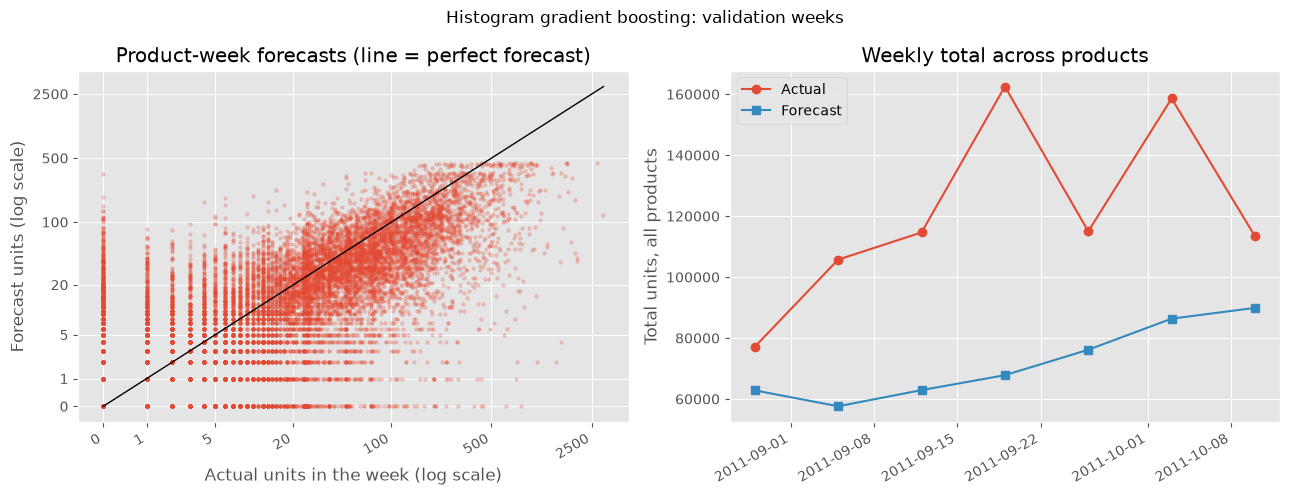

In [12]:
def plot_forecasts(frame, forecast, title, path):
    """Left: each product-week; right: total units per week across all products."""
    actual = frame[TARGET].to_numpy()
    predicted = np.rint(np.clip(forecast, 0, None))
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    ax = axes[0]
    ax.scatter(np.log1p(actual), np.log1p(predicted), s=6, alpha=0.25)
    limit = np.log1p(max(actual.max(), predicted.max()))
    ax.plot([0, limit], [0, limit], color='black', linewidth=1)
    ticks = [0, 1, 5, 20, 100, 500, 2500]
    ticks = [t for t in ticks if np.log1p(t) <= limit]
    ax.set_xticks(np.log1p(ticks)); ax.set_xticklabels(ticks)
    ax.set_yticks(np.log1p(ticks)); ax.set_yticklabels(ticks)
    ax.set_xlabel('Actual units in the week (log scale)')
    ax.set_ylabel('Forecast units (log scale)')
    ax.set_title('Product-week forecasts (line = perfect forecast)')
    weekly = pd.DataFrame({'WeekStart': frame.WeekStart.to_numpy(), 'actual': actual, 'forecast': predicted}) \
        .groupby('WeekStart').sum()
    ax = axes[1]
    ax.plot(weekly.index, weekly.actual, marker='o', label='Actual')
    ax.plot(weekly.index, weekly.forecast, marker='s', label='Forecast')
    ax.set_ylabel('Total units, all products')
    ax.set_title('Weekly total across products')
    ax.legend()
    fig.autofmt_xdate()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.show()


plot_forecasts(validation, val_forecast, f'{SELECTED}: validation weeks', FIG_DIR / 'validation_forecasts.png')

### Which features does the chosen model rely on?

Permutation importance on the validation weeks: shuffle one predictor at a time and measure how much MAE gets worse. Only features the chosen model actually uses are listed, and the product code (when used) is permuted as a single feature, not as thousands of dummies. A larger increase means the model leans on that feature more. This describes the fitted model, not a causal effect. The month indicators show no effect here because the validation months (August to October) have little or no training history.

,Feature,MAE increase when shuffled,Std over repeats
0,RollingMean4,8.847,0.066
1,UnitsLag1,5.542,0.078
2,UnitsLag2,2.204,0.034
3,UnitsLag4,1.228,0.014
4,ZeroWeeksLast4,1.185,0.086
5,LastObservedUnitPrice,0.140,0.016
6,RollingStd4,0.104,0.008
7,PriorSellingWeeks,0.079,0.006
8,WeeksSinceFirstSale,0.036,0.002
9,WeekCos,0.002,0.000


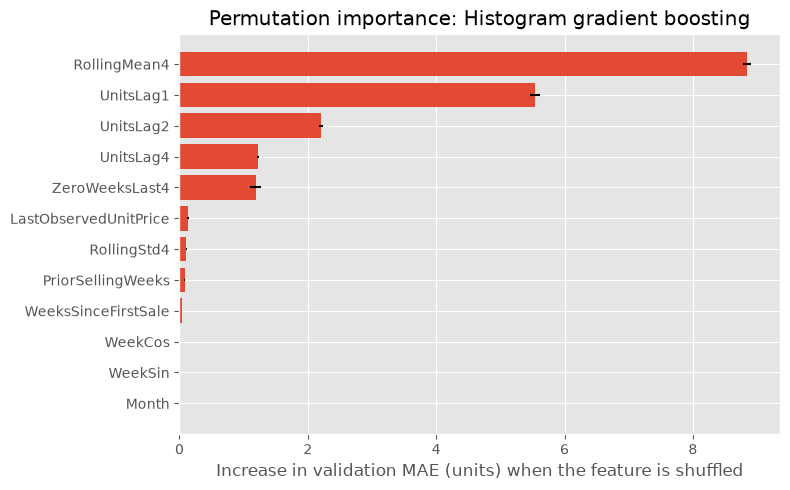

In [13]:
USED_FEATURES = NUMERIC_FEATURES + ['Month'] + (['StockCode'] if SELECTED_INCLUDE_PRODUCT else [])
importance = permutation_importance(selected_search.best_estimator_, validation[USED_FEATURES], validation[TARGET],
                                    scoring=MAE_SCORER, n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importance_table = pd.DataFrame({
    'Feature': USED_FEATURES,
    'MAE increase when shuffled': importance.importances_mean,
    'Std over repeats': importance.importances_std,
}).sort_values('MAE increase when shuffled', ascending=False).reset_index(drop=True)
importance_table['Model'] = SELECTED
display(importance_table[['Feature', 'MAE increase when shuffled', 'Std over repeats']].round(3))

fig, ax = plt.subplots(figsize=(8, 5))
plot_table = importance_table.iloc[::-1]
ax.barh(plot_table.Feature, plot_table['MAE increase when shuffled'], xerr=plot_table['Std over repeats'])
ax.set_xlabel('Increase in validation MAE (units) when the feature is shuffled')
ax.set_title(f'Permutation importance: {SELECTED}')
fig.tight_layout()
fig.savefig(FIG_DIR / 'permutation_importance.png', dpi=130)
plt.show()

## 7. Final evaluation on the reserved test weeks

The model and its settings are now locked. The chosen configuration is **refit on training + validation weeks**, with the imputer, scaler and product vocabulary re-learned from that combined past partition only, so the model has seen the most recent weeks before the test period begins. It is then scored on the test weeks **once**.

The test weeks (17 October to 28 November 2011) cover the pre-Christmas peak, so sales volumes are higher than anything in the training weeks. This is a deliberately hard check of how the model copes when demand moves beyond what it has seen.

In [14]:
train_validation = development.loc[development.Split.isin(['train', 'validation'])].reset_index(drop=True)
final_model = clone(selected_search.best_estimator_)      # same settings, unfitted
final_model.fit(train_validation[FEATURES], train_validation[TARGET])

holdout = development.loc[development.Split.eq('test')].reset_index(drop=True)
assert train_validation.WeekStart.max() < holdout.WeekStart.min()
scaler = final_model.named_steps['preprocess'].named_transformers_['numeric'].named_steps['scale']
assert scaler.n_samples_seen_ == len(train_validation), 'preprocessing was not fit on train + validation only'

test_forecast = final_model.predict(holdout[FEATURES])
test_baselines = baseline_forecasts(train_validation, holdout)

test_rows = [dict(forecast_metrics(holdout[TARGET], test_forecast), Model=SELECTED, Role='Final model (train + validation refit)')]
for name, forecast in test_baselines.items():
    test_rows.append(dict(forecast_metrics(holdout[TARGET], forecast), Model=name, Role='Baseline'))
test_comparison = pd.DataFrame(test_rows)
display(test_comparison[['Model', 'Role', 'MAE', 'RMSE', 'R2', 'WAPE', 'Within20pct', 'Within20pct_or_5units',
                         'MeanError']].round(3))

final_metrics = test_comparison.iloc[0]
for name in BASELINE_NAMES:
    base = test_comparison.loc[test_comparison.Model.eq(name)].iloc[0]
    print(f'MAE vs {name}: {final_metrics.MAE:.2f} vs {base.MAE:.2f} ({final_metrics.MAE / base.MAE - 1:+.1%})')
selected_validation = validation_comparison.loc[validation_comparison.Model.eq(SELECTED)].iloc[0]
print(f'\nSelected model MAE: validation {selected_validation.MAE:.2f} (fit on train) -> test {final_metrics.MAE:.2f} (fit on train + validation)')

,Model,Role,MAE,RMSE,R2,WAPE,Within20pct,Within20pct_or_5units,MeanError
0,Histogram gradient boosting,Final model (train + validation refit),27.659,116.851,0.355,0.588,0.371,0.587,-16.868
1,Per-product training mean,Baseline,35.477,122.200,0.295,0.754,0.192,0.458,-13.394
2,Last week (lag 1),Baseline,33.002,117.760,0.345,0.701,0.364,0.554,-1.259
3,Four-week rolling mean,Baseline,28.973,98.392,0.543,0.616,0.343,0.559,-1.908


MAE vs Per-product training mean: 27.66 vs 35.48 (-22.0%)
MAE vs Last week (lag 1): 27.66 vs 33.00 (-16.2%)
MAE vs Four-week rolling mean: 27.66 vs 28.97 (-4.5%)

Selected model MAE: validation 24.74 (fit on train) -> test 27.66 (fit on train + validation)


In [15]:
known_in_history = set(train_validation.StockCode)
test_tables, test_detail = diagnostics(holdout, test_forecast, test_baselines[BASELINE_NAMES[2]], known_in_history)
print(f'Test weeks, selected model: {SELECTED}. Baseline: four-week rolling mean. "MAE change" is negative when the model is better.')
for title, table in test_tables.items():
    print(f'\nBy {title.lower()}:')
    display(table.round(3))
zero_weeks_test = test_detail[test_detail[TARGET].eq(0)]
print(f"\nOf {len(zero_weeks_test):,} test weeks with zero actual sales, the model forecast exactly zero in "
      f"{(zero_weeks_test.forecast == 0).mean():.1%} (four-week-average baseline: {(zero_weeks_test.baseline == 0).mean():.1%}).")

weekly_test = holdout.assign(forecast=np.rint(np.clip(test_forecast, 0, None))).groupby('WeekStart') \
    .agg(actual_units=(TARGET, 'sum'), forecast_units=('forecast', 'sum'))
weekly_test['total_error_pct'] = weekly_test.forecast_units / weekly_test.actual_units - 1
print('\nWeekly totals across all products (test weeks):')
display(weekly_test.round(3))

Test weeks, selected model: Histogram gradient boosting. Baseline: four-week rolling mean. "MAE change" is negative when the model is better.

By volume group:


,Rows,Mean actual units,Model MAE,Baseline MAE,Model mean error,MAE change vs baseline
Volume group,,,,,,
under 5 units/week,10594,2.663,2.482,2.582,-1.949,-0.039
5 to 20,4356,17.240,13.454,13.947,-8.663,-0.035
20 to 100,5502,53.458,32.896,35.580,-16.779,-0.075
over 100,3059,231.662,125.662,129.881,-80.375,-0.032



By product:


,Rows,Mean actual units,Model MAE,Baseline MAE,Model mean error,MAE change vs baseline
Product,,,,,,
new product,838,61.346,33.402,40.190,-17.557,-0.169
seen in training,22673,46.517,27.447,28.558,-16.842,-0.039



By weeks:


,Rows,Mean actual units,Model MAE,Baseline MAE,Model mean error,MAE change vs baseline
Weeks,,,,,,
actual sales = 0,7945,0.000,1.813,4.609,1.813,-0.607
actual sales > 0,15566,71.058,40.851,41.408,-26.402,-0.013



Of 7,945 test weeks with zero actual sales, the model forecast exactly zero in 75.3% (four-week-average baseline: 64.6%).

Weekly totals across all products (test weeks):


,actual_units,forecast_units,total_error_pct
WeekStart,,,
2011-10-17,145207.0,96732.0,-0.334
2011-10-24,142876.0,91277.0,-0.361
2011-10-31,154030.0,96247.0,-0.375
2011-11-07,175423.0,94679.0,-0.460
2011-11-14,181697.0,103520.0,-0.430
2011-11-21,152949.0,111123.0,-0.273
2011-11-28,153901.0,115933.0,-0.247


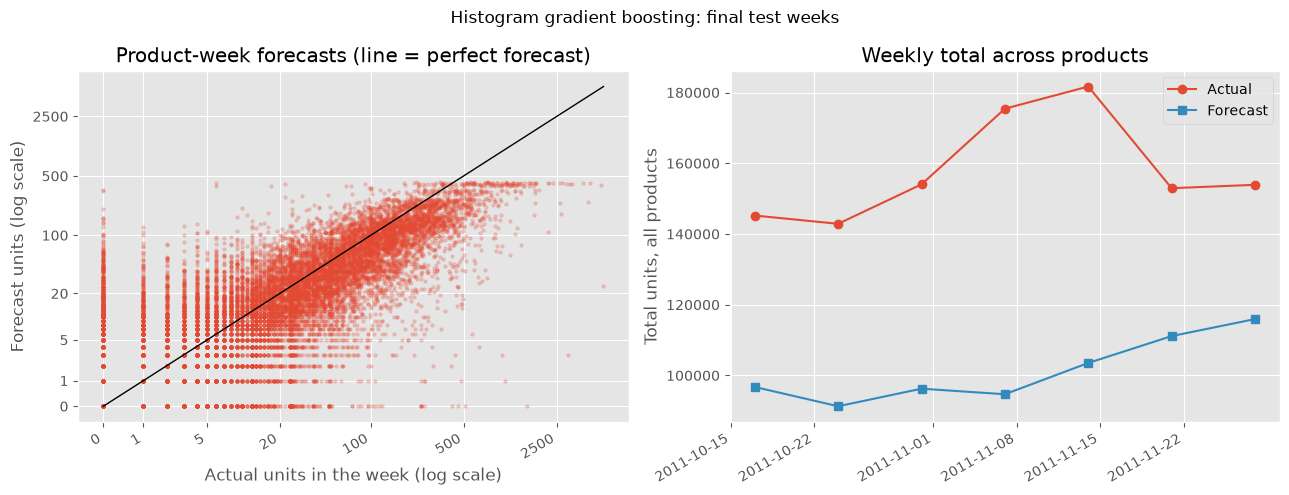

In [16]:
plot_forecasts(holdout, test_forecast, f'{SELECTED}: final test weeks', FIG_DIR / 'test_forecasts.png')

## 8. Save metrics, tuning results and predictions

Everything the written report and README need is saved to `reports/modeling/`: the combined metrics file, the tuning results, the chosen parameters, feature importance, test-week predictions and the figures above.

In [17]:
metric_columns = ['MAE', 'RMSE', 'R2', 'WAPE', 'Within20pct', 'Within20pct_or_5units', 'MeanError']
validation_out = validation_comparison[['Model', 'Role'] + metric_columns + ['CV_MAE']].copy()
validation_out.insert(0, 'Stage', 'validation (fit on train weeks)')
test_out = test_comparison[['Model', 'Role'] + metric_columns].copy()
test_out['CV_MAE'] = np.nan
test_out.insert(0, 'Stage', 'final test (fit on train + validation weeks)')
model_metrics = pd.concat([validation_out, test_out], ignore_index=True)
model_metrics.to_csv(REPORT_DIR / 'model_metrics.csv', index=False)

tuning_frames = []
for name, info in tuned.items():
    results = pd.DataFrame(info['search'].cv_results_)
    frame = pd.DataFrame({
        'Model': name,
        'Parameters': results.params.apply(lambda p: json.dumps({k.replace('model__', ''): v for k, v in p.items()}, default=str)),
        'CV_MAE_mean': -results.mean_test_score,
        'CV_MAE_std': results.std_test_score,
        'Rank': results.rank_test_score,
    })
    tuning_frames.append(frame)
pd.concat(tuning_frames, ignore_index=True).to_csv(REPORT_DIR / 'tuning_results.csv', index=False)

best_parameters = {name: {k.replace('model__', ''): v for k, v in info['search'].best_params_.items()}
                   for name, info in tuned.items()}
(REPORT_DIR / 'best_parameters.json').write_text(json.dumps(best_parameters, indent=2, default=str))
importance_table.to_csv(REPORT_DIR / 'permutation_importance.csv', index=False)

predictions = holdout[['RowID', 'StockCode', 'WeekStart', TARGET]].rename(columns={TARGET: 'ActualUnits'}).copy()
predictions['ForecastUnits'] = np.rint(np.clip(test_forecast, 0, None)).astype(int)
predictions['FourWeekMeanBaseline'] = np.rint(np.clip(test_baselines[BASELINE_NAMES[2]], 0, None)).astype(int)
predictions['ProductSeenBefore'] = holdout.StockCode.isin(known_in_history).to_numpy()
predictions.to_csv(REPORT_DIR / 'test_predictions.csv.gz', index=False, compression='gzip')

run_manifest = {
    'stage': 'modeling_v1',
    'selection_rule': 'lowest validation MAE with rounded non-negative forecasts',
    'selected_model': SELECTED,
    'selected_parameters': best_parameters[SELECTED],
    'selected_includes_product_dummies': bool(SELECTED_INCLUDE_PRODUCT),
    'ridge_includes_product_dummies': bool(RIDGE_INCLUDE_PRODUCT),
    'models_compared': list(tuned),
    'xgboost_in_run': 'XGBoost' in tuned,
    'random_state': RANDOM_STATE,
    'cv_folds': cv_summary.to_dict(orient='records'),
    'train_rows': int(len(train)), 'validation_rows': int(len(validation)), 'test_rows': int(len(holdout)),
    'python': platform.python_version(), 'packages': versions,
}
(REPORT_DIR / 'run_manifest.json').write_text(json.dumps(run_manifest, indent=2, default=str))
print('Saved to', REPORT_DIR.relative_to(REPO_ROOT))
for path in sorted(REPORT_DIR.rglob('*')):
    if path.is_file():
        print(' ', path.relative_to(REPORT_DIR), f'({path.stat().st_size / 1024:.0f} KB)')

Saved to reports/modeling
  best_parameters.json (0 KB)
  figures/permutation_importance.png (55 KB)
  figures/test_forecasts.png (230 KB)
  figures/validation_forecasts.png (260 KB)
  model_metrics.csv (2 KB)
  permutation_importance.csv (1 KB)
  run_manifest.json (2 KB)
  test_predictions.csv.gz (208 KB)
  tuning_results.csv (5 KB)


## 9. Results summary

The text below is generated from the results above, so it stays correct if the notebook is re-run (for example, after installing XGBoost).

In [18]:
base_test = {name: test_comparison.loc[test_comparison.Model.eq(name)].iloc[0] for name in BASELINE_NAMES}
vol = test_tables['Volume group']
prod = test_tables['Product']
lines = []
lines.append(f"Models compared: {', '.join(tuned)}. Selected on validation MAE: {SELECTED} "
             f"(settings: {best_parameters[SELECTED]}).")
lines.append(f"Validation weeks: {SELECTED} MAE {selected_validation.MAE:.2f} units per product-week, versus "
             f"{best_baseline_row.MAE:.2f} for the best naive rule ({best_baseline_row.Model}).")
lines.append(f"Final test weeks (train + validation refit): MAE {final_metrics.MAE:.2f}, RMSE {final_metrics.RMSE:.1f}, "
             f"R2 {final_metrics.R2:.3f}, mean error {final_metrics.MeanError:+.2f} units.")
for name in BASELINE_NAMES:
    base = base_test[name]
    change = final_metrics.MAE / base.MAE - 1
    verdict = 'better than' if change < 0 else 'worse than'
    lines.append(f"  vs {name}: MAE {final_metrics.MAE:.2f} vs {base.MAE:.2f} ({change:+.1%}), {verdict} this baseline on MAE; "
                 f"RMSE {final_metrics.RMSE:.1f} vs {base.RMSE:.1f}, R2 {final_metrics.R2:.3f} vs {base.R2:.3f}.")
lines.append(f"Share of test forecasts within 20% of actual: {final_metrics.Within20pct:.1%} strict, "
             f"{final_metrics.Within20pct_or_5units:.1%} when a miss of up to 5 units also counts "
             f"(four-week average: {base_test[BASELINE_NAMES[2]].Within20pct:.1%} and "
             f"{base_test[BASELINE_NAMES[2]].Within20pct_or_5units:.1%}).")
lines.append(f"Seen versus new products on test: MAE {prod.loc['seen in training', 'Model MAE']:.2f} on "
             f"{int(prod.loc['seen in training', 'Rows']):,} rows of seen products; "
             f"{prod.loc['new product', 'Model MAE']:.2f} on {int(prod.loc['new product', 'Rows']):,} rows of new products.")
lines.append(f"Largest-volume products (over 100 units/week): model MAE {vol.loc['over 100', 'Model MAE']:.1f} "
             f"vs {vol.loc['over 100', 'Baseline MAE']:.1f} for the four-week average; "
             f"mean error {vol.loc['over 100', 'Model mean error']:+.1f} units.")
lines.append(f"Weekly totals across all products on test: forecast units were {weekly_test.total_error_pct.min():+.0%} to "
             f"{weekly_test.total_error_pct.max():+.0%} relative to actual units, by week.")
top3 = importance_table.head(3).Feature.tolist()
lines.append(f"Most influential features on validation (permutation importance): {', '.join(top3)}.")
print('\n'.join(lines))

Models compared: Ridge regression, Random forest, Histogram gradient boosting. Selected on validation MAE: Histogram gradient boosting (settings: {'learning_rate': 0.05, 'loss': 'absolute_error', 'max_leaf_nodes': 31, 'min_samples_leaf': 20}).
Validation weeks: Histogram gradient boosting MAE 24.74 units per product-week, versus 27.31 for the best naive rule (Four-week rolling mean).
Final test weeks (train + validation refit): MAE 27.66, RMSE 116.9, R2 0.355, mean error -16.87 units.
  vs Per-product training mean: MAE 27.66 vs 35.48 (-22.0%), better than this baseline on MAE; RMSE 116.9 vs 122.2, R2 0.355 vs 0.295.
  vs Last week (lag 1): MAE 27.66 vs 33.00 (-16.2%), better than this baseline on MAE; RMSE 116.9 vs 117.8, R2 0.355 vs 0.345.
  vs Four-week rolling mean: MAE 27.66 vs 28.97 (-4.5%), better than this baseline on MAE; RMSE 116.9 vs 98.4, R2 0.355 vs 0.543.
Share of test forecasts within 20% of actual: 37.1% strict, 58.7% when a miss of up to 5 units also counts (four-week 

## 10. Limits and next steps

- **One year of data.** Training covers January to August 2011 and the test weeks fall in the autumn peak. The model cannot learn an annual cycle from a single year, and the autumn calendar-month indicators have little or no training history. Test-week volumes are higher than anything in training, so test error partly measures how the model copes with a regime shift.
- **Sales are not demand.** Recorded sales understate demand when a product was out of stock, and a product with no sales may have been discontinued. The forecast is of recorded units.
- **Intermittent demand.** Many products sell in only some weeks. Rounded forecasts handle zeros reasonably but not sporadic bulk orders, which dominate RMSE.
- **New products.** Products with fewer than four prior selling weeks are out of scope by design. Products first seen in the holdout without a training vocabulary rely entirely on their recent history.
- **Choosing on MAE can leave a bias.** A model picked for the lowest average miss can still be biased in total volume, especially when demand moves beyond the training range. Check the mean error and the weekly-total table in Section 7 before using the forecasts to set stock levels, and discuss with your mentor whether the selection rule should also constrain bias (or use RMSE or a quantile target).
- **Tuning scale.** The grids are small, the folds are short, and the choice between close candidates is partly noise. Differences of a few percent in MAE between models should not be over-interpreted.
- **Not yet done.** Prediction intervals, per-product safety-stock rules, the Streamlit dashboard from the proposal, and a check of any chosen model against a second year of data.

### Sources
- Preprocessing and splits: `03_preprocessing_and_training_data.ipynb` and `PREPROCESSING.md` in this repository.
- Chen, D. (2015). [Online Retail dataset, UCI](https://doi.org/10.24432/C5BW33), CC BY 4.0.
- [scikit-learn: Tuning the hyper-parameters of an estimator](https://scikit-learn.org/stable/modules/grid_search.html) and [Permutation feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html).
